# Phase 3: Simulated Annealing (Target Shape Morphing)
**Objective:** Morph the `dino` dataset into the `star` dataset using a stochastic optimization algorithm. The algorithm will minimize the spatial distance between the two shapes while strictly rejecting any movement that alters the baseline mean, variance, or Pearson correlation beyond a 0.01 tolerance.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(42)

### 1. Load Cleaned Data and Isolate Targets

In [11]:
df = pd.read_csv('../Data/Cleaned_Data/datasaurus_clean.csv')

dino = df[df['dataset'] == 'dino'].copy()
star = df[df['dataset'] == 'star'].copy()

print(f"Dino:\n{dino}\n---------------------------------\n Star:\n{star}")

Dino:
    dataset        x        y
0      dino  55.3846  97.1795
1      dino  51.5385  96.0256
2      dino  46.1538  94.4872
3      dino  42.8205  91.4103
4      dino  40.7692  88.3333
..      ...      ...      ...
137    dino  39.4872  25.3846
138    dino  91.2821  41.5385
139    dino  50.0000  95.7692
140    dino  47.9487  95.0000
141    dino  44.1026  92.6923

[142 rows x 3 columns]
---------------------------------
 Star:
    dataset          x          y
710    star  58.213608  91.881892
711    star  58.196054  92.214989
712    star  58.718231  90.310532
713    star  57.278373  89.907607
714    star  58.082020  92.008145
..      ...        ...        ...
847    star  43.722551  19.077328
848    star  79.326078  52.900391
849    star  56.663974  87.940125
850    star  57.821789  90.693167
851    star  58.243172  92.104328

[142 rows x 3 columns]


In [12]:
dino_x = dino['x'].values
dino_y = dino['y'].values
target_x = star['x'].values
target_y = star['y'].values

print(f"Starting shape (dino) points: {len(dino_x)}")
print(f"Target shape (star) points: {len(target_x)}")

Starting shape (dino) points: 142
Target shape (star) points: 142


### 2. Declare Pure NumPy Statistical Functions

In [13]:
def compute_mean(arr: np.ndarray) -> float:
    return np.sum(arr) / len(arr)

def compute_sample_variance(arr: np.ndarray, mean_val: float) -> float:
    return np.sum((arr - mean_val) ** 2) / (len(arr) - 1)

def compute_correlation(x: np.ndarray, y: np.ndarray, mean_x: float, mean_y: float) -> float:
    numerator = np.sum((x - mean_x) * (y - mean_y))
    denominator = np.sqrt(np.sum((x - mean_x) ** 2) * np.sum((y - mean_y) ** 2))
    return numerator / denominator

### 3. Establish the Immutable Baseline Constraints

In [14]:
base_mean_x = compute_mean(dino_x)
base_mean_y = compute_mean(dino_y)
base_var_x = compute_sample_variance(dino_x, base_mean_x)
base_var_y = compute_sample_variance(dino_y, base_mean_y)
base_corr = compute_correlation(dino_x, dino_y, base_mean_x, base_mean_y)

print(f"Baseline Mean (X, Y): {base_mean_x:.4f}, {base_mean_y:.4f}")
print(f"Baseline Variance (X, Y): {base_var_x:.4f}, {base_var_y:.4f}")
print(f"Baseline Correlation: {base_corr:.4f}")

Baseline Mean (X, Y): 54.2633, 47.8323
Baseline Variance (X, Y): 281.0700, 725.5160
Baseline Correlation: -0.0645


### 4. Define the Cost Function (Spatial Distance)

In [15]:
def calculate_cost(current_x: np.ndarray, current_y: np.ndarray, target_x: np.ndarray, target_y: np.ndarray) -> float:
    """
    Calculates the total distance from each current point to the nearest target point.
    Lower cost = closer to the star shape.
    """
    total_cost = 0
    for i in range(len(current_x)):
        distances = np.sqrt((target_x - current_x[i])**2 + (target_y - current_y[i])**2)
        total_cost += np.min(distances)
    return total_cost

initial_cost = calculate_cost(dino_x, dino_y, target_x, target_y)
print(f"Initial Cost (Distance from Dino to Star): {initial_cost:.2f}")

Initial Cost (Distance from Dino to Star): 1103.72


### 5. Execute the Simulated Annealing Optimization Engine
*Note: This loop executes 30,000 iterations to slowly cool the system. It may take 1-2 minutes to process.*

In [23]:
iterations = 150000      
temp = 100.0             
cooling_rate = 0.9995    
tolerance = 0.1    
perturb_amount = 0.1  

curr_x = dino_x.copy()
curr_y = dino_y.copy()
curr_cost = initial_cost

print("Starting Simulated Annealing...")

for i in range(iterations):
    idx = np.random.randint(0, len(curr_x))
    
    old_x, old_y = curr_x[idx], curr_y[idx]
    
    curr_x[idx] += np.random.normal(0, perturb_amount)
    curr_y[idx] += np.random.normal(0, perturb_amount)
    
    new_mean_x = compute_mean(curr_x)
    new_mean_y = compute_mean(curr_y)
    new_var_x = compute_sample_variance(curr_x, new_mean_x)
    new_var_y = compute_sample_variance(curr_y, new_mean_y)
    new_corr = compute_correlation(curr_x, curr_y, new_mean_x, new_mean_y)
    
    if (abs(new_mean_x - base_mean_x) > tolerance or
        abs(new_mean_y - base_mean_y) > tolerance or
        abs(new_var_x - base_var_x) > tolerance or
        abs(new_var_y - base_var_y) > tolerance or
        abs(new_corr - base_corr) > tolerance):
        
        curr_x[idx], curr_y[idx] = old_x, old_y
        continue 
        
    new_cost = calculate_cost(curr_x, curr_y, target_x, target_y)
    cost_diff = new_cost - curr_cost
    
    if cost_diff < 0:
        curr_cost = new_cost
    else:
        acceptance_probability = np.exp(-cost_diff / temp)
        if np.random.random() < acceptance_probability:
            curr_cost = new_cost
        else:
            curr_x[idx], curr_y[idx] = old_x, old_y
            
    temp *= cooling_rate
    
    if i % 10000 == 0:
        print(f"Iteration {i} | Temp: {temp:.2f} | Cost: {curr_cost:.2f}")

print(f"\nOptimization Complete. Final Cost: {curr_cost:.2f}")

Starting Simulated Annealing...
Iteration 0 | Temp: 99.95 | Cost: 1103.80
Iteration 10000 | Temp: 1.74 | Cost: 1106.24
Iteration 20000 | Temp: 0.04 | Cost: 1011.25
Iteration 30000 | Temp: 0.00 | Cost: 842.08
Iteration 40000 | Temp: 0.00 | Cost: 714.38
Iteration 60000 | Temp: 0.00 | Cost: 522.88
Iteration 90000 | Temp: 0.00 | Cost: 383.19
Iteration 100000 | Temp: 0.00 | Cost: 348.04
Iteration 110000 | Temp: 0.00 | Cost: 315.20
Iteration 120000 | Temp: 0.00 | Cost: 295.46
Iteration 130000 | Temp: 0.00 | Cost: 265.65
Iteration 140000 | Temp: 0.00 | Cost: 240.00

Optimization Complete. Final Cost: 216.86


### 6. Verify Final Statistics Against Baseline

In [21]:
final_mean_x = compute_mean(curr_x)
final_mean_y = compute_mean(curr_y)
final_var_x = compute_sample_variance(curr_x, final_mean_x)
final_var_y = compute_sample_variance(curr_y, final_mean_y)
final_corr = compute_correlation(curr_x, curr_y, final_mean_x, final_mean_y)

print("--- FINAL STATS VERIFICATION ---")
print(f"Mean (X, Y): {final_mean_x:.4f}, {final_mean_y:.4f} (Target: {base_mean_x:.4f}, {base_mean_y:.4f})")
print(f"Variance (X, Y): {final_var_x:.4f}, {final_var_y:.4f} (Target: {base_var_x:.4f}, {base_var_y:.4f})")
print(f"Correlation: {final_corr:.4f} (Target: {base_corr:.4f})")

--- FINAL STATS VERIFICATION ---
Mean (X, Y): 54.3631, 47.9318 (Target: 54.2633, 47.8323)
Variance (X, Y): 280.9864, 725.4769 (Target: 281.0700, 725.5160)
Correlation: -0.0179 (Target: -0.0645)


### 7. Visual Confirmation (Dino vs. Morphed Star)

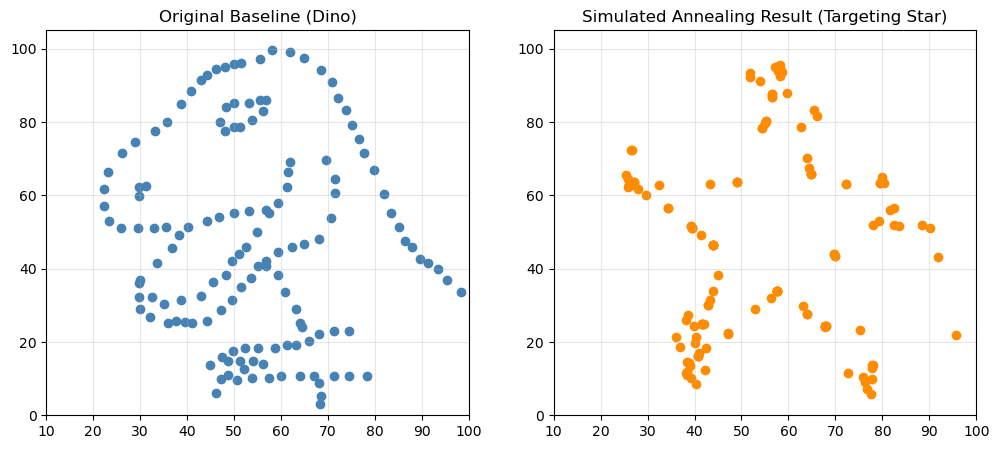

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(dino_x, dino_y, color='steelblue')
axes[0].set_title('Original Baseline (Dino)')
axes[0].set_xlim(10, 100)
axes[0].set_ylim(0, 105)
axes[0].grid(alpha=0.3)

axes[1].scatter(curr_x, curr_y, color='darkorange')
axes[1].set_title('Simulated Annealing Result (Targeting Star)')
axes[1].set_xlim(10, 100)
axes[1].set_ylim(0, 105)
axes[1].grid(alpha=0.3)

plt.show()